In [1]:
import os
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    log_loss,
)
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from scipy import stats as sstats
from catboost import CatBoostRegressor, CatBoostClassifier

REPO_ROOT = Path.cwd().parent
# make the shared code in src/ importable even when the package is not pip-installed
if str(REPO_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / "src"))

from egypt_survey_ml.config import DatasetConfig
from egypt_survey_ml.dataset import prepare_dataset

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

In [2]:
# --- scenario settings -------------------------------------------------
# Every value below can be changed to test a different scenario. Defaults live in
# src/egypt_survey_ml/config.py (DatasetConfig); anything left out keeps its default
# (rng_seed=42, min_working_age=15, weeks_per_month=365.25/7/12).
# Column-selection workbook, separate from the command-area data_filename below.
# Sheet1: variable = column name, correl = 1 to include (0 to exclude), type = binary/
# categorical/numerical; remarks is ignored. Selected columns that are not in the data are
# skipped (same as the training notebooks). The saved models always get the columns they
# were trained on, so the mask only sets the default feature set of the dataset.
MASK_PATH = (
    Path.home()
    / "OneDrive - Stichting Deltares"
    / "Tiaravanni Hermawan's files - Egypt_ERF_data/Data/variable_selection.xlsx"
)

cfg = DatasetConfig(
    include_empstab=True,   # see design-decisions table above: circular under the zero-inclusive regime
    include_hrswk=True,     # team decision (Vanni's email) excludes hours for the female model;
                            # the audit branch's train-catboost_raw*.ipynb notebooks all keep it
                            # for female too. Toggle this to test how much of their higher
                            # reported R2 comes from that one feature, holding everything else
                            # (repeated eval, intensive-margin decomposition, wage formula, cap)
                            # fixed at our more rigorous setup.
    zero_handling="drop_random",   # one of: "none", "drop_random", "lognormal_synthetic"
    predict_log_wage=False,
    include_ribasim=True,
    wage_perturbation=False,
    wage_perturbation_sigma=0.03,
    drop_random_frac=1.0,   # only used when zero_handling == "drop_random"
    n_reps=100,             # change this
    male_outlier_cap=5000,
    female_outlier_cap=4000,
    data_filename="data_correlation.xlsx",
)

In [3]:
# Loads the survey, builds household wage context, makes the sex-stratified train/test split and the
# wage target, attaches governorates, and loads the command-area data and feature mask
# (see src/egypt_survey_ml/dataset.py).
ds = prepare_dataset(cfg, mask_path=MASK_PATH)

train_pool = ds.train_pool
test_pool = ds.test_pool
survey_columns = ds.survey_columns
excel_df = ds.excel_df
EXCEL_PATH = ds.paths.excel_path

# dataset-bound helpers used by the cells below
assign_command_units = ds.assign_command_units
build_feature_frame = ds.build_feature_frame
apply_zero_handling = ds.apply_zero_handling

data source: OneDrive (/Users/hemert/OneDrive - Stichting Deltares/Tiaravanni Hermawan's files - Egypt/04_Data/2026_data)
OK   /Users/hemert/OneDrive - Stichting Deltares/Tiaravanni Hermawan's files - Egypt/04_Data/2026_data/Labor Force Survey, LFS 2022 - Egypt, Arab Rep., 2022/Egypt 2022-LFS IND-V1.dta
OK   /Users/hemert/OneDrive - Stichting Deltares/Tiaravanni Hermawan's files - Egypt/04_Data/2026_data/Labor Force Survey, LFS 2022 - Egypt, Arab Rep., 2022/Egypt 2022-LFS HH-V1.dta
OK   /Users/hemert/OneDrive - Stichting Deltares/Tiaravanni Hermawan's files - Egypt/04_Data/cleaned_data/crosswalk/reg_governorate_crosswalk.csv
OK   /Users/hemert/OneDrive - Stichting Deltares/Tiaravanni Hermawan's files - Egypt/04_Data/cleaned_data/crosswalk/command_area_governorate_crosswalk.csv
OK   /Users/hemert/OneDrive - Stichting Deltares/Tiaravanni Hermawan's files - Egypt_ERF_data/Data/variable_selection.xlsx
OK   /Users/hemert/OneDrive - Stichting Deltares/Tiaravanni Hermawan's files - Egypt/04_D

In [6]:
# One example draw (seed 0) of the training frame, for exploring the data in the cells below
from egypt_survey_ml.dataset import TARGET_COLS

train_geo = ds.assign_command_units(train_pool, seed=0)
train_frame, cats, _ = ds.build_feature_frame(train_geo, sex_code=2)
feature_cols = [c for c in train_frame.columns if c not in TARGET_COLS]

In [5]:
def evaluate(y_true_wage, y_pred_wage, is_paid_true, label=""):
    rmse = mean_squared_error(y_true_wage, y_pred_wage) ** 0.5
    metrics = {
        "label": label,
        "n": len(y_true_wage),
        "mae": mean_absolute_error(y_true_wage, y_pred_wage),
        "rmse": rmse,
        "r2": r2_score(y_true_wage, y_pred_wage),
        "spearman": sstats.spearmanr(y_true_wage, y_pred_wage).correlation,
        "mean_pred_at_true_zero": y_pred_wage[is_paid_true == 0].mean() if (is_paid_true == 0).any() else np.nan,
        "mean_pred_at_true_positive": y_pred_wage[is_paid_true == 1].mean() if (is_paid_true == 1).any() else np.nan,
        "mean_actual_at_true_positive": y_true_wage[is_paid_true == 1].mean() if (is_paid_true == 1).any() else np.nan,
    }
    pos = is_paid_true == 1
    if pos.sum() > 1:
        metrics["intensive_mae"] = mean_absolute_error(y_true_wage[pos], y_pred_wage[pos])
        metrics["intensive_rmse"] = mean_squared_error(y_true_wage[pos], y_pred_wage[pos]) ** 0.5
        metrics["intensive_r2"] = r2_score(y_true_wage[pos], y_pred_wage[pos])
    return metrics

def evaluate_participation(y_true, p_pred, threshold=0.5, label=""):
    y_pred = (p_pred >= threshold).astype(int)

    return {
        "label": label,
        "n": len(y_true),
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "auc": roc_auc_score(y_true, p_pred),
        "pr_auc": average_precision_score(y_true, p_pred),
        "logloss": log_loss(y_true, p_pred),
        "pred_positive_rate": y_pred.mean(),
        "actual_positive_rate": y_true.mean(),
    }

def gender_gap(pred_male, pred_female, actual_male, actual_female):
    return {
        "predicted_gap": pred_male.mean() - pred_female.mean(),
        "observed_gap": actual_male.mean() - actual_female.mean(),
    }


In [7]:
def fit_and_predict(train_frame, test_frame, feature_cols, cat_cols, iterations=500, learning_rate=0.05, depth=6, early_stopping_rounds=None, use_best_model=None):
    # Fit directly on raw wage (the fix -- see the title cell). No log1p/expm1 round-trip:
    # that round-trip was diagnosed as the main source of the systematic under-prediction
    # in train-catboost_v2_rural.ipynb (predictions ~1/5 to 1/12 of actual paid-mean wage).
    X_train = train_frame[feature_cols]
    y_train = train_frame["totwag_all"]
    X_test = test_frame[feature_cols]
    y_test = test_frame["totwag_all"]
    model = CatBoostRegressor(
        iterations=iterations, learning_rate=learning_rate, depth=depth, loss_function="RMSE",
        random_seed=42, verbose=False,
    )
    model.fit(
        X_train, 
        y_train, 
        cat_features=cat_cols,
        eval_set=(X_train, y_train),
        use_best_model=use_best_model,
        early_stopping_rounds=early_stopping_rounds
    )
    pred_wage = model.predict(X_test)
    return model, np.clip(pred_wage, 0, None)  # wage can't be negative; CatBoost's raw output can be

def fit_and_predict_classifier(train_frame, test_frame, feature_cols, cat_cols, iterations=500, learning_rate=0.05, depth=6, early_stopping_rounds=None, use_best_model=None):
    X_train = train_frame[feature_cols]
    y_train = train_frame["is_paid"]
    X_test = test_frame[feature_cols]
    y_test = test_frame["is_paid"]
    model = CatBoostClassifier(
        iterations=iterations, learning_rate=learning_rate, depth=depth,
        random_seed=42, verbose=False,
    )
    model.fit(
        X_train, 
        y_train, 
        cat_features=cat_cols,
        eval_set=(X_train, y_train),
        use_best_model=use_best_model,
        early_stopping_rounds=early_stopping_rounds
    )
    pred_paid = model.predict(X_test)
    return model, pred_paid


LAST_MODELS = {}  # populated as a side effect of run_once(), for the SHAP cell below --
                  # always reflects whichever run_once() call executed most recently.

LAST_MODELS_CLASSIFIER = {}

def run_once(seed, iterations=500, learning_rate=0.05, depth=6, early_stopping_rounds=None, use_best_model=None, sex_label=None):
    train_geo = ds.assign_command_units(train_pool, seed=seed)
    test_geo = ds.assign_command_units(test_pool, seed=seed)
    if sex_label is None:
        model_options = [(1, "male"), (2, "female")]
    elif sex_label == "male":
        model_options = [(1, "male")]
    elif sex_label == "female":
        model_options = [(2, "female")]
    
    results = {}
    preds = {}
    for sex_code, sex_label in model_options:
        train_frame = ds.realization(sex_label, seed, test_data=False).frame
        test_frame = ds.realization(sex_label, seed, test_data=True).frame

        model, pred_wage = fit_and_predict(train_frame, test_frame, feature_cols, cats, learning_rate=learning_rate, depth=depth, early_stopping_rounds=early_stopping_rounds, use_best_model=use_best_model)
        m = evaluate(test_frame["totwag_all"].to_numpy(), pred_wage, test_frame["is_paid"].to_numpy(), label=sex_label)
        results[sex_label] = m
        preds[sex_label] = (pred_wage, test_frame["totwag_all"].to_numpy())
        LAST_MODELS[sex_label] = {
            "model": model, "X_test": test_frame[feature_cols], "cat_features": cats,
            "y_test": test_frame["totwag_all"].to_numpy(), "y_pred": pred_wage,
        }

    if sex_label is None:
        gap = gender_gap(preds["male"][0], preds["female"][0], preds["male"][1], preds["female"][1])
    else:
        gap = {}
    return results, gap, LAST_MODELS

def run_once_classifier(seed, iterations=500, learning_rate=0.05, depth=6, early_stopping_rounds=None, use_best_model=None, sex_label=None):
    train_geo = assign_command_units(train_pool, seed)
    test_geo = assign_command_units(test_pool, seed)
    if sex_label is None:
        model_options = [(1, "male"), (2, "female")]
    elif sex_label == "male":
        model_options = [(1, "male")]
    elif sex_label == "female":
        model_options = [(2, "female")]

    results = {}
    preds = {}
    for sex_code, sex_label in model_options:
        train_frame, cats = build_feature_frame(train_geo, sex_code)
        test_frame, _ = build_feature_frame(test_geo, sex_code)
        feature_cols = [c for c in train_frame.columns if c not in ("log1p_wage", "totwag_all", "is_paid")]
        if not INCLUDE_RIBASIM:
            feature_cols = [c for c in feature_cols if c in survey_columns]
            cats = [c for c in cats if c in survey_columns]
        # train_frame = apply_zero_handling(train_frame, cats, feature_cols, ZERO_HANDLING, seed)

        model, pred_paid = fit_and_predict_classifier(train_frame, test_frame, feature_cols, cats, learning_rate=learning_rate, depth=depth, early_stopping_rounds=early_stopping_rounds, use_best_model=use_best_model)
        m = evaluate_participation(test_frame["is_paid"].to_numpy(), pred_paid, label=sex_label)
        results[sex_label] = m
        preds[sex_label] = (pred_paid, test_frame["is_paid"].to_numpy())
        LAST_MODELS_CLASSIFIER[sex_label] = {
            "model": model, "X_test": test_frame[feature_cols], "cat_features": cats,
            "y_test": test_frame["is_paid"].to_numpy(), "y_pred": pred_paid,
        }


    if sex_label is None:
        gap = gender_gap(preds["male"][0], preds["female"][0], preds["male"][1], preds["female"][1])
    else:
        gap = {}
    return results, gap, LAST_MODELS_CLASSIFIER

# Comparison log: persists across re-runs of THIS cell (guarded), so toggling a setting and
# re-running Section 7 + this cell repeatedly accumulates one row per gender per
# configuration tried, instead of overwriting the previous result. Re-run just this "if"
# line yourself (or restart the kernel) if you deliberately want to clear it.
if "comparison_log" not in globals():
    comparison_log = []

_results, _gap, _ = run_once(42)
print(pd.DataFrame(_results).T)
print()
print("Gender gap (EGP/month), predicted vs. observed:", _gap)

_config_label = f"EMPSTAB={True}, HRSWK={True}, ZERO={"drop_random"!r}"
for _sex_label, _m in _results.items():
    comparison_log.append({"config": _config_label, **_m})
print(f"\nLogged this run as {_config_label!r} -- comparison_log has {len(comparison_log)} rows "
      f"({len(comparison_log)//2} configurations tried this session). See Section 10c to visualize."
      )

         label     n         mae        rmse        r2  spearman mean_pred_at_true_zero mean_pred_at_true_positive mean_actual_at_true_positive intensive_mae  \
male      male  2091  477.306789  644.818062   0.39284   0.63925                    NaN                2419.788995                   2422.08667    477.306789   
female  female    98  425.021393  551.784492  0.418325  0.641703                    NaN                 1924.78193                  1908.520386    425.021393   

       intensive_rmse intensive_r2  
male       644.818062      0.39284  
female     551.784492     0.418325  

Gender gap (EGP/month), predicted vs. observed: {}

Logged this run as "EMPSTAB=True, HRSWK=True, ZERO='drop_random'" -- comparison_log has 2 rows (1 configurations tried this session). See Section 10c to visualize.


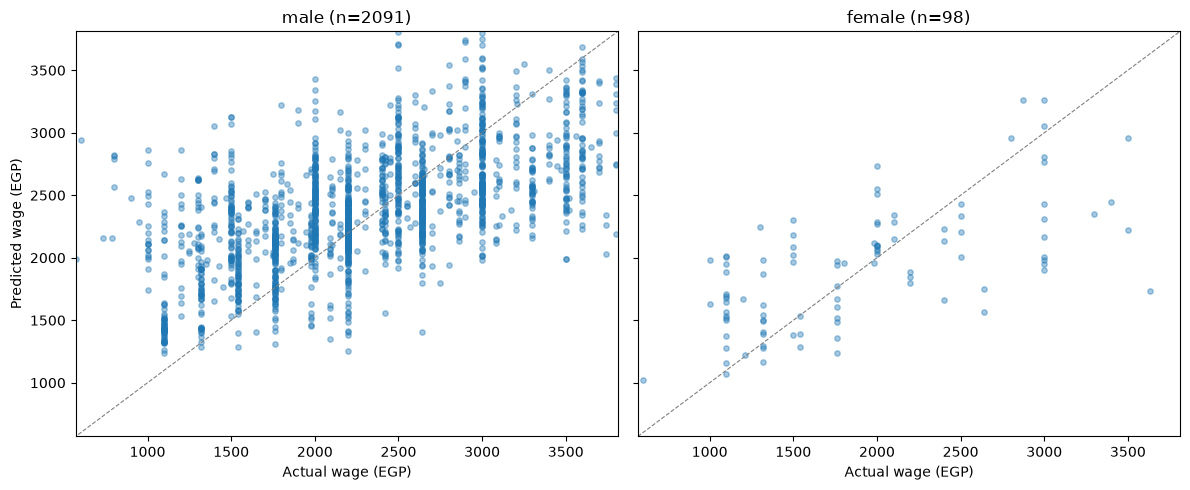

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
for ax, sex_label in zip(axes, ["male", "female"]):
    info = LAST_MODELS[sex_label]
    y_true, y_pred = info["y_test"], info["y_pred"]
    ax.scatter(y_true, y_pred, alpha=0.4, s=15)
    lims = [0.95 * min(y_true.min(), y_pred.min()), max(y_true.max(), y_pred.max()) * 1.05]
    ax.plot(lims, lims, color="gray", linestyle="--", linewidth=0.8)
    ax.set_xlim(lims)
    ax.set_ylim(lims)
    ax.set_xlabel("Actual wage (EGP)")
    ax.set_title(f"{sex_label} (n={len(y_true)})")
axes[0].set_ylabel("Predicted wage (EGP)")
plt.tight_layout()
plt.show()


In [9]:
MASK_PATH.is_absolute()

True